In [2]:
from google.colab import drive
import shutil
from pathlib import Path

drive.mount("/content/drive")

PROJECT_DIR = Path("/content/drive/MyDrive/arsenal_transformer")
DATA_DIR = PROJECT_DIR / "data";    DATA_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = PROJECT_DIR / "outputs";  OUT_DIR.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
!pip install pybaseball lightgbm torch pyarrow scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 426.1/426.1 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.6/455.6 kB 26.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.2 MB/s eta 0:00:00


In [3]:
import pandas as pd

SEASONS = [2024, 2025,2026]

raw = pd.concat(
    [pd.read_parquet(DATA_DIR / f"raw_{y}.parquet") for y in SEASONS],
    ignore_index=True)
print(f"{len(raw):,} rows")

2,270,048 rows


In [4]:
import numpy as np

LABEL_MAP = {
    "FF": "FF", "SI": "SI", "FC": "FC",                # fastballs
    "SL": "SL", "ST": "ST", "SV": "SV",                # slider, sweeper, slurve
    "CU": "CU", "CS": "CU", "KC": "KC",                # curveballs (slow curve -> CU)
    "CH": "CH", "FS": "FS", "FO": "FS",                # offspeed (forkball -> FS)
}
MERGE_SWEEPER_INTO_SLIDER = False

RAW_COLS = [
    "pitcher", "p_throws", "game_date", "game_pk", "game_year", "game_type",
    "at_bat_number", "pitch_number", "pitch_type",
    "release_speed", "release_spin_rate", "spin_axis",
    "pfx_x", "pfx_z", "release_pos_x", "release_pos_z", "release_extension",
    "arm_angle", "vx0", "vz0", "ax", "az",
]
PITCH_FEATURES = [
    "release_speed", "release_spin_rate", "spin_axis_sin", "spin_axis_cos",
    "pfx_x_in", "pfx_z_in", "release_pos_x", "release_pos_z", "release_extension",
    "arm_angle", "arm_angle_missing", "vx0", "vz0", "ax", "az",
]
SEED = 42

def clean(df):
    df = df.copy()
    for col in RAW_COLS:              # newer columns (e.g. arm_angle) may be missing
        if col not in df.columns:
            df[col] = np.nan

    df = df[df["game_type"] == "R"]
    df["label"] = df["pitch_type"].map(LABEL_MAP)
    if MERGE_SWEEPER_INTO_SLIDER:
        df.loc[df["label"] == "ST", "label"] = "SL"
    df = df[df["label"].notna()]

    num_cols = ["release_speed", "release_spin_rate", "spin_axis", "pfx_x", "pfx_z",
                "release_pos_x", "release_pos_z", "release_extension", "arm_angle",
                "vx0", "vz0", "ax", "az"]
    df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")
    df = df.dropna(subset=[c for c in num_cols if c != "arm_angle"] + ["pitcher", "p_throws"])

    lefty = df["p_throws"] == "L"
    for col in ["pfx_x", "release_pos_x", "vx0", "ax"]:
        df.loc[lefty, col] = -df.loc[lefty, col]
    df.loc[lefty, "spin_axis"] = (360 - df.loc[lefty, "spin_axis"]) % 360

    rad = np.deg2rad(df["spin_axis"])
    df["spin_axis_sin"], df["spin_axis_cos"] = np.sin(rad), np.cos(rad)
    df["pfx_x_in"], df["pfx_z_in"] = df["pfx_x"] * 12, df["pfx_z"] * 12
    df["arm_angle_missing"] = df["arm_angle"].isna().astype(np.float32)

    df["game_date"] = pd.to_datetime(df["game_date"])
    df["game_year"] = df["game_date"].dt.year
    df = df.sort_values(["pitcher", "game_date", "game_pk", "at_bat_number", "pitch_number"])
    df["group_id"] = df.groupby(["pitcher", "game_year"]).ngroup()
    df = df[df.groupby("group_id")["group_id"].transform("size") >= 20]
    return df.reset_index(drop=True)

def split_by_pitcher(df, val_frac=0.15, test_frac=0.15):
    rng = np.random.default_rng(SEED)
    pitchers = df["pitcher"].unique()
    rng.shuffle(pitchers)
    n_test, n_val = int(len(pitchers) * test_frac), int(len(pitchers) * val_frac)
    split = pd.Series("train", index=pitchers)
    split.iloc[:n_test] = "test"
    split.iloc[n_test:n_test + n_val] = "val"
    df["split"] = df["pitcher"].map(split)

    med = df.loc[df["split"] == "train", "arm_angle"].median()   # train-only statistic
    df["arm_angle"] = df["arm_angle"].fillna(0.0 if np.isnan(med) else med)
    return df


df = split_by_pitcher(clean(raw))
del raw

CLASSES = sorted(df["label"].unique())
TO_IDX = {c: i for i, c in enumerate(CLASSES)}
df["y"] = df["label"].map(TO_IDX)

print(f"{len(df):,} pitches | {df['pitcher'].nunique():,} pitchers | "
      f"{df['group_id'].nunique():,} pitcher-seasons")
display(df.groupby("split")["pitcher"].nunique().rename("pitchers").to_frame())
display(df["label"].value_counts(normalize=True).round(3).to_frame())

/tmp/ipykernel_4794/1068483016.py:63: UserWarning: you are shuffling a 'IntegerArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(pitchers)


2,118,922 pitches | 1,175 pitchers | 2,401 pitcher-seasons


,pitchers
split,
test,176
train,823
val,176


,proportion
label,
FF,0.316
SI,0.160
SL,0.142
CH,0.106
FC,0.079
ST,0.078
CU,0.065
FS,0.033
KC,0.017


In [5]:
def add_relative_features(df):
    df = df.copy()
    g = df.groupby("group_id")
    hard = df["release_speed"] >= g["release_speed"].transform("quantile", 0.9)
    ref_cols = ["release_speed", "release_spin_rate", "pfx_x_in", "pfx_z_in",
                "release_pos_x", "release_pos_z", "release_extension",
                "spin_axis_sin", "spin_axis_cos"]
    ref = df[hard].groupby("group_id")[ref_cols].mean().add_prefix("ref_")
    df = df.join(ref, on="group_id")

    rel = []
    for c in ref_cols[:7]:
        df[f"d_{c}"] = df[c] - df[f"ref_{c}"]
        rel.append(f"d_{c}")
    axis = np.rad2deg(np.arctan2(df["spin_axis_sin"], df["spin_axis_cos"]))
    ref_axis = np.rad2deg(np.arctan2(df["ref_spin_axis_sin"], df["ref_spin_axis_cos"]))
    df["d_spin_axis"] = (axis - ref_axis + 180) % 360 - 180   # circular difference
    df["speed_ratio"] = df["release_speed"] / df["ref_release_speed"]
    rel += ["d_spin_axis", "speed_ratio", "ref_release_speed"]
    return df, rel


df_rel, rel_cols = add_relative_features(df)
BASE_FEATURES = PITCH_FEATURES + rel_cols
Xb = df_rel[BASE_FEATURES].to_numpy(np.float32)
yb = df_rel["y"].to_numpy()
#tr, va, te = (df_rel["split"] == s for s in ["train", "val", "test"])

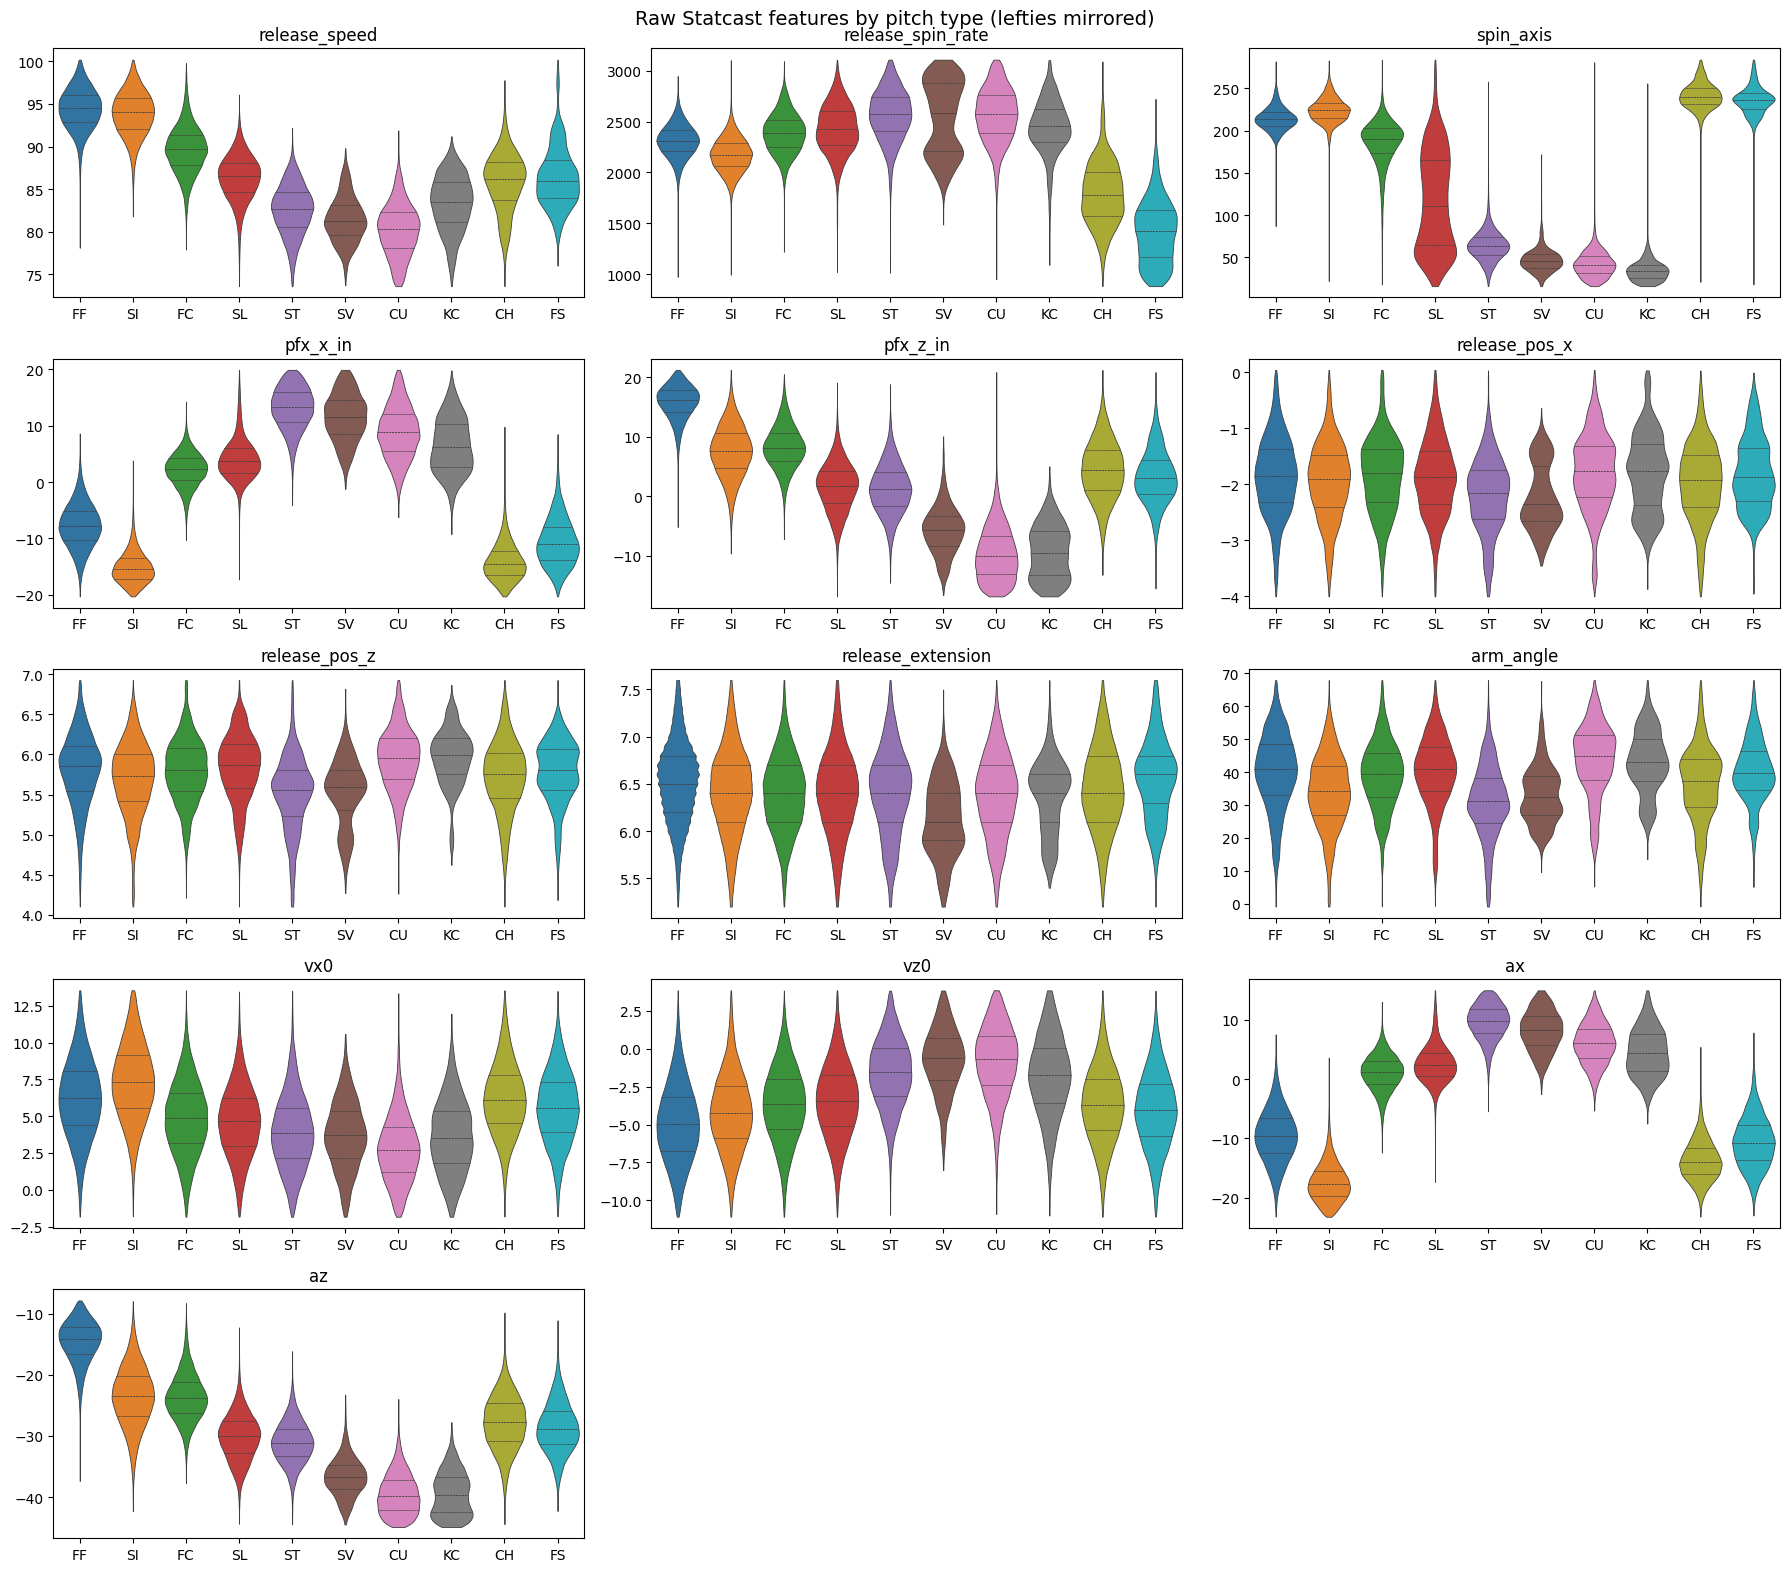

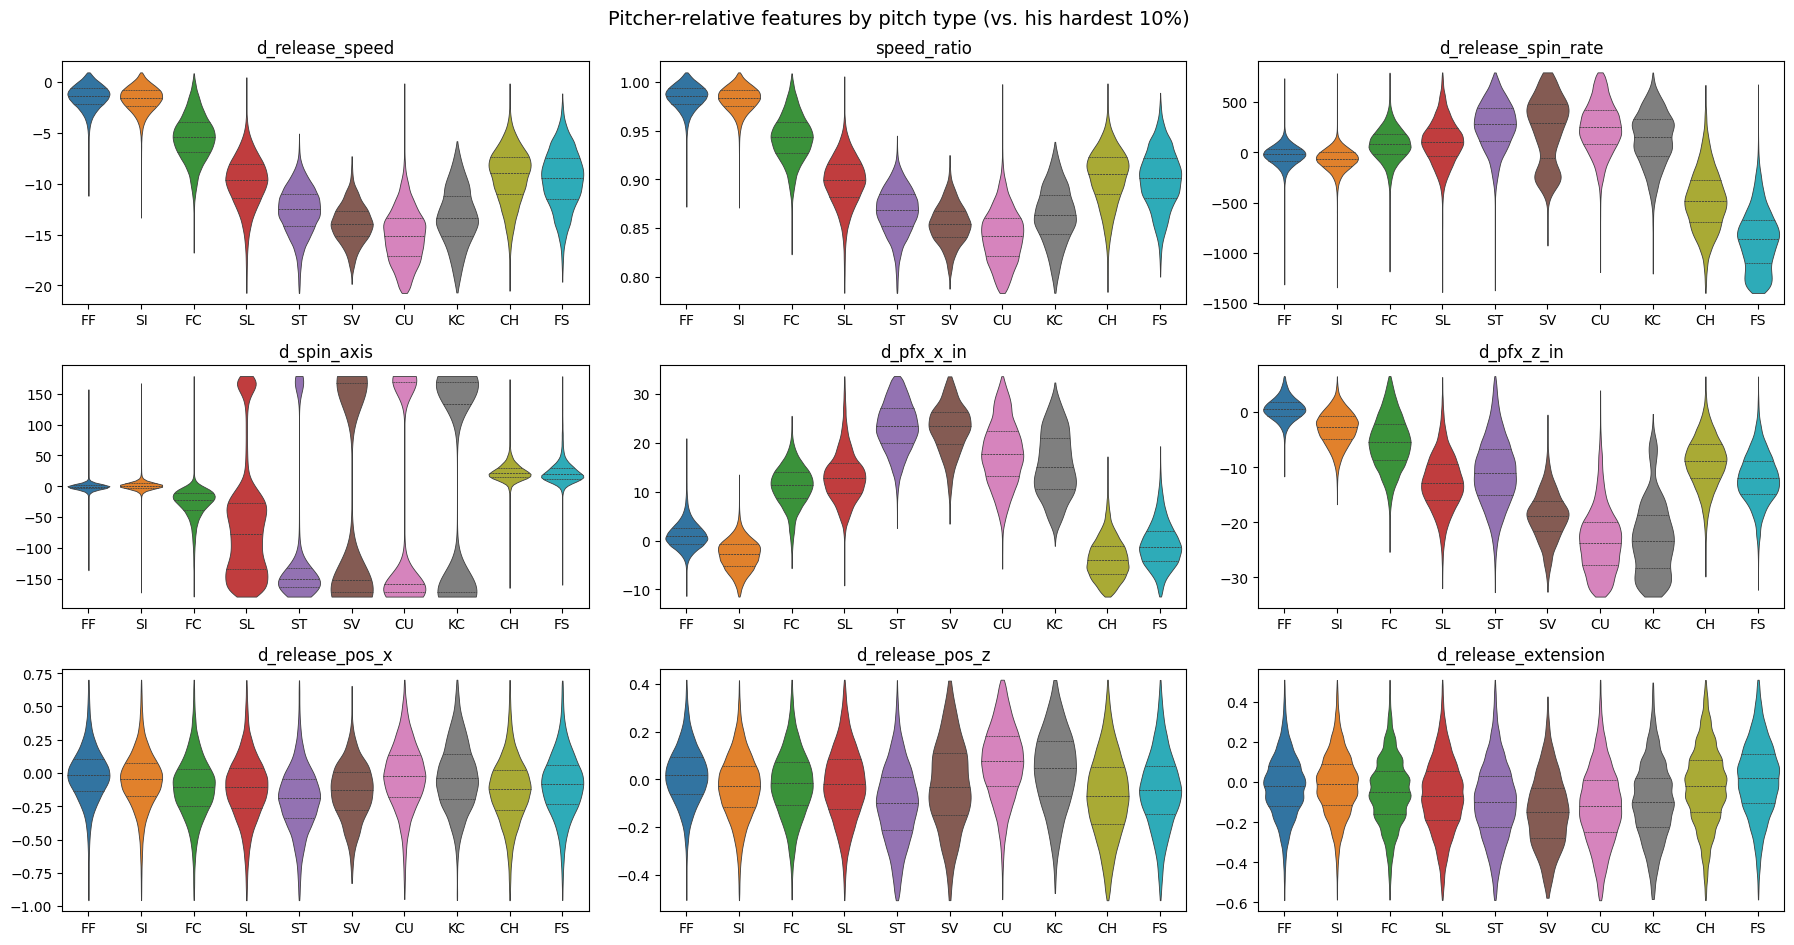

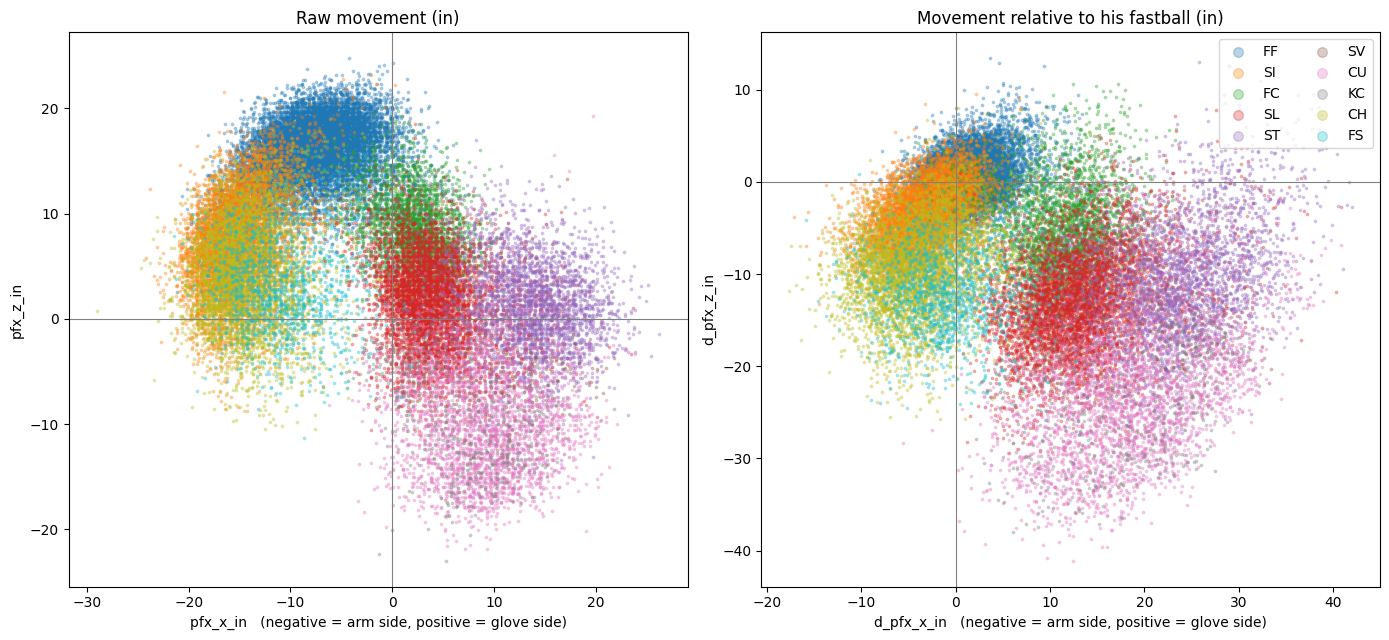

In [6]:
# Paste into a new cell AFTER the baseline feature cell (needs df, CLASSES, SEED,
# and add_relative_features from the notebook).
import math

import matplotlib.pyplot as plt
import seaborn as sns

ORDER = [p for p in ["FF", "SI", "FC", "SL", "ST", "SV", "CU", "KC", "CH", "FS"] if p in CLASSES]
PALETTE = dict(zip(ORDER, sns.color_palette("tab10", len(ORDER))))

# df_rel was deleted at the end of the baseline cell, so rebuild it if needed.
data = df_rel if "df_rel" in globals() else add_relative_features(df)[0]
# Train split only (don't look at test data), sampled so plotting stays fast.
train = data[data["split"] == "train"]
plot_df = train.sample(n=min(300_000, len(train)), random_state=SEED)

RAW_FEATURES = ["release_speed", "release_spin_rate", "spin_axis",
                "pfx_x_in", "pfx_z_in", "release_pos_x", "release_pos_z",
                "release_extension", "arm_angle", "vx0", "vz0", "ax", "az"]
REL_FEATURES = ["d_release_speed", "speed_ratio", "d_release_spin_rate", "d_spin_axis",
                "d_pfx_x_in", "d_pfx_z_in", "d_release_pos_x", "d_release_pos_z",
                "d_release_extension"]


def violin_grid(cols, title, ncols=3):
    nrows = math.ceil(len(cols) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.2 * nrows))
    for ax, col in zip(axes.flat, cols):
        lo, hi = plot_df[col].quantile([0.005, 0.995])  # trim extreme outliers
        d = plot_df[plot_df[col].between(lo, hi)]
        sns.violinplot(data=d, x="label", y=col, order=ORDER, hue="label",
                       palette=PALETTE, legend=False, cut=0, inner="quartile",
                       density_norm="width", linewidth=0.6, ax=ax)
        ax.set_title(col)
        ax.set_xlabel("")
        ax.set_ylabel("")
    for ax in axes.flat[len(cols):]:
        ax.set_visible(False)
    fig.suptitle(title, fontsize=14)
    fig.tight_layout()
    plt.show()


violin_grid(RAW_FEATURES, "Raw Statcast features by pitch type (lefties mirrored)")
violin_grid(REL_FEATURES, "Pitcher-relative features by pitch type (vs. his hardest 10%)")

# Movement charts: raw movement vs. movement relative to the pitcher's fastball.
s = plot_df.sample(n=min(40_000, len(plot_df)), random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, (x, y, title) in zip(axes, [
        ("pfx_x_in", "pfx_z_in", "Raw movement (in)"),
        ("d_pfx_x_in", "d_pfx_z_in", "Movement relative to his fastball (in)")]):
    for p in ORDER:
        sub = s[s["label"] == p]
        ax.scatter(sub[x], sub[y], s=3, alpha=0.3, color=PALETTE[p], label=p)
    ax.axhline(0, color="gray", lw=0.8)
    ax.axvline(0, color="gray", lw=0.8)
    ax.set_xlabel(f"{x}   (negative = arm side, positive = glove side)")
    ax.set_ylabel(y)
    ax.set_title(title)
axes[1].legend(markerscale=4, ncol=2, loc="upper right")
fig.tight_layout()
plt.show()

,pitches,speed,HB (in),IVB (in),spin,pitchers
label,,,,,,
FF,669211,94.5,-7.8,15.7,2311.6,1766
SI,339344,93.7,-15.1,7.5,2179.2,1180
FC,167218,89.7,2.2,8.1,2398.6,672


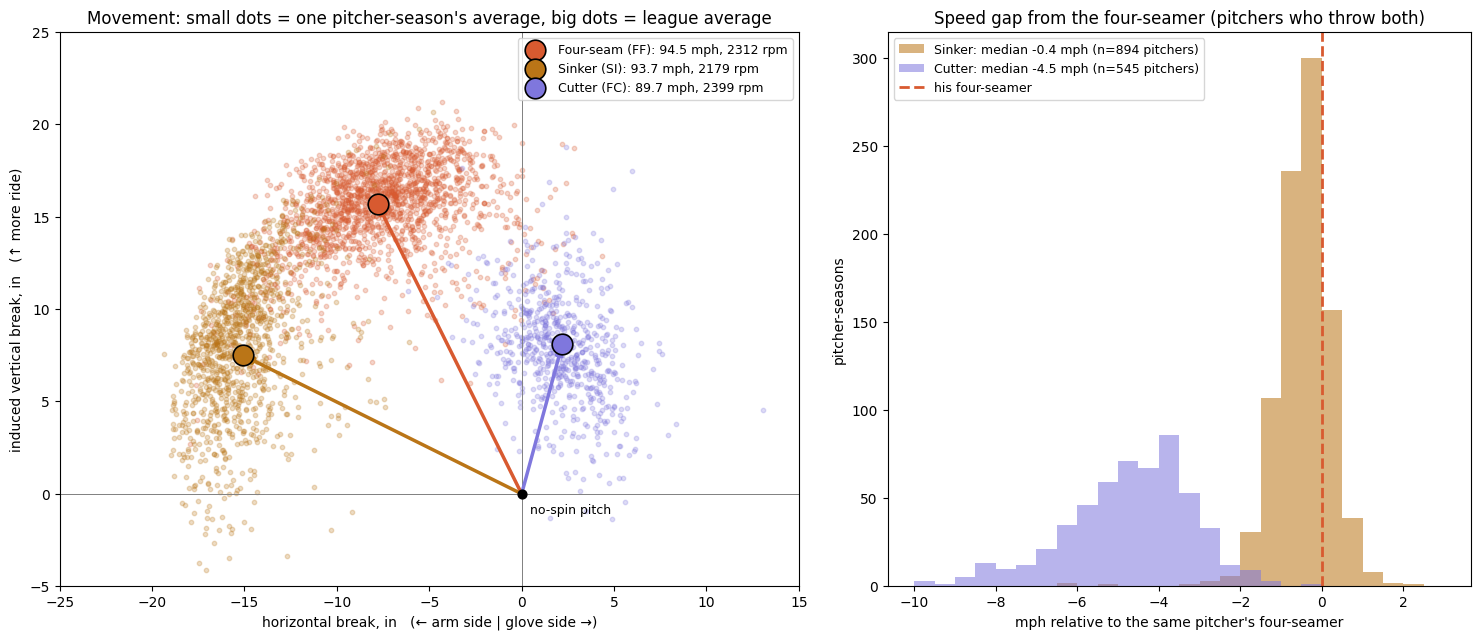

In [7]:
# FF vs SI vs FC from your own data. Paste into a new cell after the cleaning cell
# (needs df and SEED). Lefties are mirrored, so this is everyone in a right-hander's
# view from the catcher: negative = arm side, positive = glove side.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

TYPES = {"FF": ("Four-seam", "#D85A30"), "SI": ("Sinker", "#BA7517"), "FC": ("Cutter", "#7F77DD")}
MIN_PITCHES = 50   # per pitcher-season, so each dot is a stable average

sub = df[df["label"].isin(TYPES)]

# One dot per pitcher-season per pitch type
arsenal = (sub.groupby(["group_id", "label"])
              .agg(n=("release_speed", "size"), speed=("release_speed", "mean"),
                   hb=("pfx_x_in", "mean"), ivb=("pfx_z_in", "mean"),
                   spin=("release_spin_rate", "mean"))
              .reset_index())
arsenal = arsenal[arsenal["n"] >= MIN_PITCHES]

# League-wide summary (pitch-weighted)
summary = (sub.groupby("label")
              .agg(pitches=("release_speed", "size"), speed=("release_speed", "mean"),
                   hb=("pfx_x_in", "mean"), ivb=("pfx_z_in", "mean"),
                   spin=("release_spin_rate", "mean"))
              .reindex(list(TYPES)).round(1))
summary["pitchers"] = arsenal.groupby("label")["group_id"].nunique()
display(summary.rename(columns={"hb": "HB (in)", "ivb": "IVB (in)"}))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})

# Left: movement chart
for code, (name, color) in TYPES.items():
    a = arsenal[arsenal["label"] == code]
    ax.scatter(a["hb"], a["ivb"], s=10, alpha=0.25, color=color)
    m = summary.loc[code]
    ax.annotate("", xy=(m["hb"], m["ivb"]), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2.5))
    ax.scatter(m["hb"], m["ivb"], s=220, color=color, edgecolor="black", lw=1.2, zorder=5,
               label=f'{name} ({code}): {m["speed"]:.1f} mph, {m["spin"]:.0f} rpm')
ax.scatter(0, 0, s=40, color="black", zorder=5)
ax.annotate("no-spin pitch", (0, 0), xytext=(6, -14), textcoords="offset points", fontsize=9)
ax.axhline(0, color="gray", lw=0.7)
ax.axvline(0, color="gray", lw=0.7)
ax.set_xlim(-25, 15)
ax.set_ylim(-5, 25)
ax.set_aspect("equal")
ax.set_xlabel("horizontal break, in   (← arm side | glove side →)")
ax.set_ylabel("induced vertical break, in   (↑ more ride)")
ax.set_title("Movement: small dots = one pitcher-season's average, big dots = league average")
ax.legend(loc="upper right", fontsize=9)

# Right: speed relative to the same pitcher's four-seamer
ff_speed = arsenal[arsenal["label"] == "FF"].set_index("group_id")["speed"]
rel = arsenal[arsenal["label"].isin(["SI", "FC"])].join(ff_speed.rename("ff_speed"), on="group_id")
rel = rel.dropna(subset=["ff_speed"])
rel["gap"] = rel["speed"] - rel["ff_speed"]
bins = np.arange(-10, 3.5, 0.5)
for code in ["SI", "FC"]:
    name, color = TYPES[code]
    g = rel.loc[rel["label"] == code, "gap"]
    ax2.hist(g, bins=bins, alpha=0.55, color=color,
             label=f"{name}: median {g.median():+.1f} mph (n={len(g)} pitchers)")
ax2.axvline(0, color="#D85A30", lw=2, ls="--", label="his four-seamer")
ax2.set_xlabel("mph relative to the same pitcher's four-seamer")
ax2.set_ylabel("pitcher-seasons")
ax2.set_title("Speed gap from the four-seamer (pitchers who throw both)")
ax2.legend(fontsize=9)

fig.tight_layout()
plt.show()

270 cutters and 263 sliders in (87.5, 91.0) mph
3 example pairs found
Gathering player lookup table. This may take a moment.


,pair,called,pitcher,year,speed,HB (in),IVB (in),spin,axis,usage,his FB,gap from FB,IVB drop vs FB
0,1,CUTTER,Marcus Stroman,2024,88.1,1.0,5.8,2531.5,193.4,0.2,SI 90.0,1.8,-2.6
1,1,SLIDER,Eury Pérez,2026,88.5,1.0,5.2,2434.3,174.0,0.2,FF 98.2,9.7,12.9
2,2,CUTTER,Sonny Gray,2024,87.7,5.5,0.9,2708.4,113.4,0.2,FF 92.4,4.7,11.2
3,2,SLIDER,Chase Dollander,2026,87.6,6.2,-0.4,2709.1,111.3,0.1,FF 98.9,11.3,13.3
4,3,CUTTER,John Schreiber,2024,88.7,-1.3,6.0,2320.5,222.1,0.2,SI 92.0,3.3,-8.0
5,3,SLIDER,Elvis Alvarado,2025,88.9,-0.9,5.5,2215.8,249.2,0.3,FF 98.7,9.8,8.2


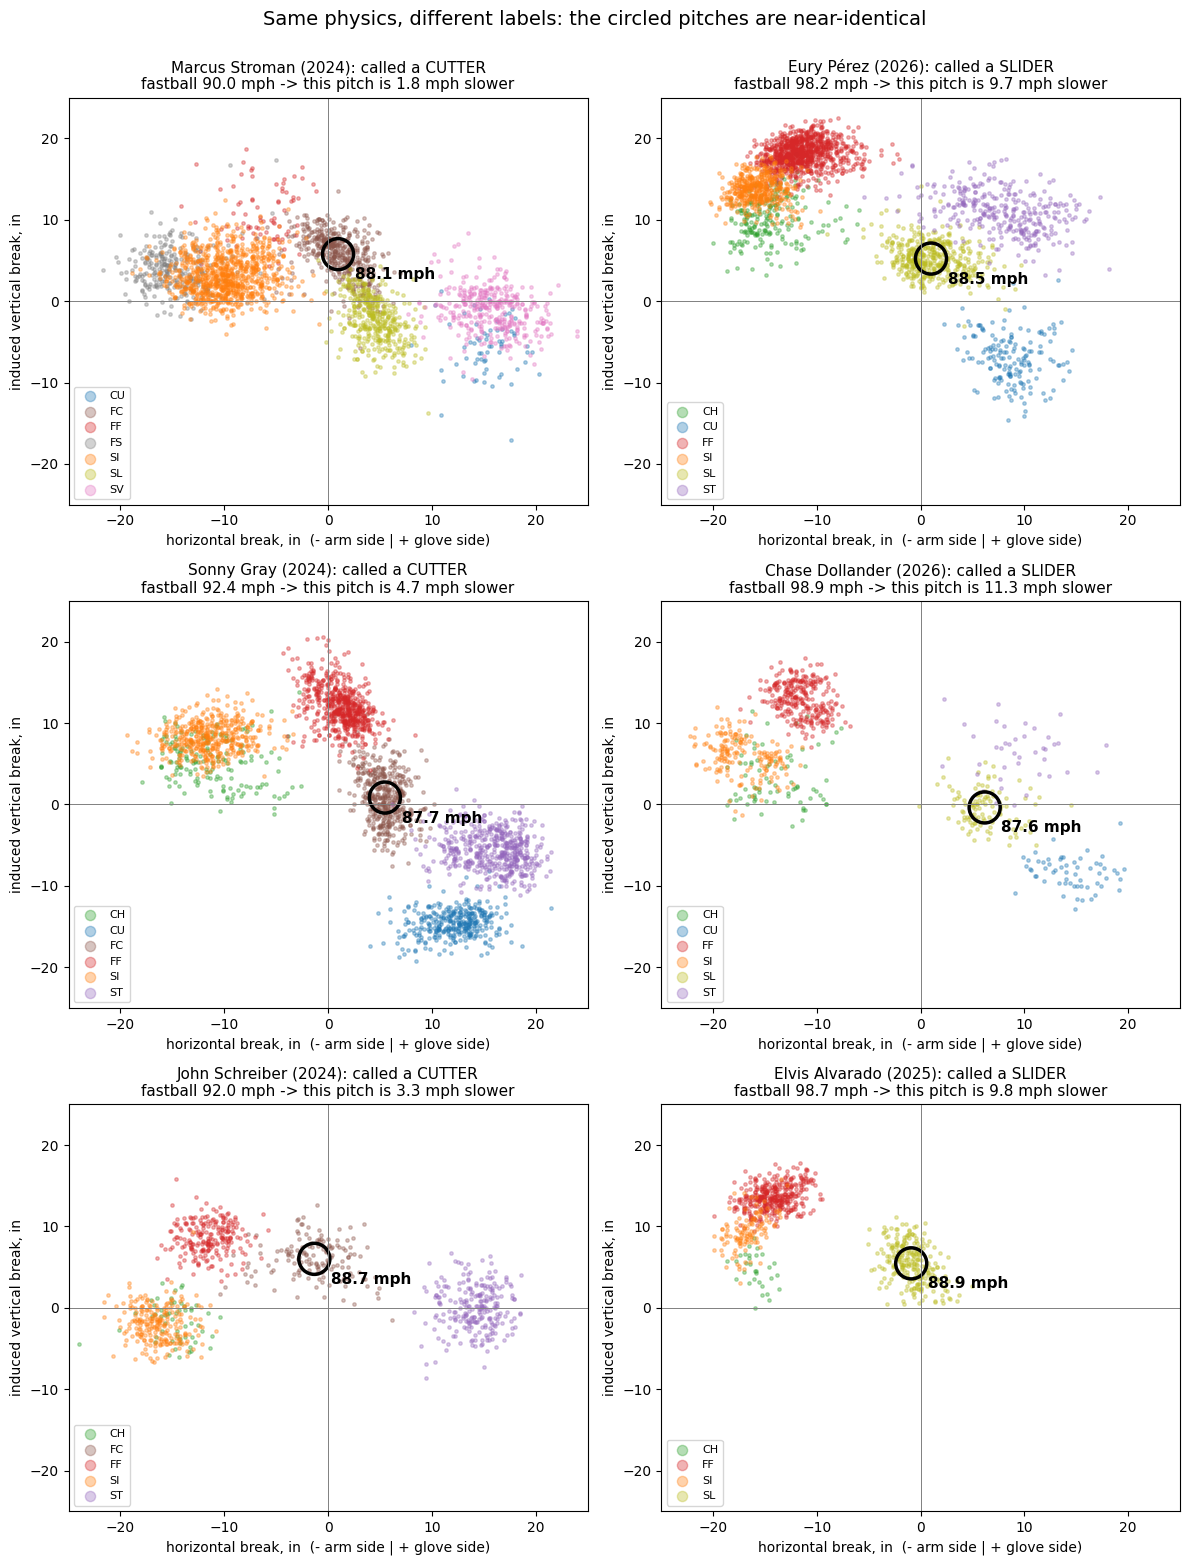

In [10]:
# @title
# Find a pitcher's CUTTER and another pitcher's SLIDER that are nearly identical
# physically, then show that their fastballs (the context) are what differ.
# Paste into a new cell after the baseline feature cell (needs df, SEED,
# add_relative_features). Uses labels freely: this is exploration, not modeling.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SPEED_RANGE = (87.5, 91.0)   # "around 89 mph"
MIN_PITCHES = 100            # only well-established pitches
N_EXAMPLES = 3

data = df_rel if "df_rel" in globals() else add_relative_features(df)[0]

# 1) Average profile of every pitch type in every arsenal (pitcher-season)
prof = (data.groupby(["group_id", "pitcher", "game_year", "label"])
            .agg(n=("release_speed", "size"),
                 speed=("release_speed", "mean"),
                 hb=("pfx_x_in", "mean"),          # + = glove side (lefties mirrored)
                 ivb=("pfx_z_in", "mean"),
                 spin=("release_spin_rate", "mean"),
                 ax_sin=("spin_axis_sin", "mean"),
                 ax_cos=("spin_axis_cos", "mean"))
            .reset_index())
prof["axis"] = np.rad2deg(np.arctan2(prof["ax_sin"], prof["ax_cos"])) % 360
prof["usage"] = prof["n"] / prof.groupby("group_id")["n"].transform("sum")

# 2) Each arsenal's primary fastball (most-used FF or SI)
fb = (prof[prof["label"].isin(["FF", "SI"])]
          .sort_values("n", ascending=False)
          .drop_duplicates("group_id")
          .set_index("group_id")[["label", "speed", "hb", "ivb"]]
          .add_prefix("fb_"))
prof = prof.join(fb, on="group_id").dropna(subset=["fb_speed"])
prof["gap"] = prof["fb_speed"] - prof["speed"]   # mph slower than his fastball

def candidates(label):
    m = ((prof["label"] == label) & (prof["n"] >= MIN_PITCHES)
         & prof["speed"].between(*SPEED_RANGE))
    return prof[m].reset_index(drop=True)

fc, sl = candidates("FC"), candidates("SL")
print(f"{len(fc)} cutters and {len(sl)} sliders in {SPEED_RANGE} mph")

# 3) Compare every cutter with every slider; scale = what counts as "the same"
scale = {"speed": 1.0, "hb": 2.0, "ivb": 2.0, "spin": 150.0}
dist2 = sum(((fc[c].to_numpy()[:, None] - sl[c].to_numpy()[None, :]) / s) ** 2
            for c, s in scale.items())
i, j = np.nonzero(np.sqrt(dist2) < 1.0)                       # physically look-alike
pairs = pd.DataFrame({"i": i, "j": j, "dist": np.sqrt(dist2[i, j])})
pairs = pairs[fc.loc[pairs["i"], "pitcher"].to_numpy() != sl.loc[pairs["j"], "pitcher"].to_numpy()]
# Most interesting: cutter thrown close to its fastball, slider far below its fastball
pairs["contrast"] = sl.loc[pairs["j"], "gap"].to_numpy() - fc.loc[pairs["i"], "gap"].to_numpy()
pairs = pairs[pairs["contrast"] >= 3].sort_values("contrast", ascending=False)
# One example per pitcher so the list isn't the same guy repeated
pairs = pairs.drop_duplicates("i").drop_duplicates("j").head(N_EXAMPLES)
print(f"{len(pairs)} example pairs found")

# 4) Player names (needs internet; falls back to IDs)
ids = pd.concat([fc.loc[pairs["i"], "pitcher"], sl.loc[pairs["j"], "pitcher"]]).unique()
try:
    from pybaseball import playerid_reverse_lookup
    lk = playerid_reverse_lookup(list(map(int, ids)), key_type="mlbam")
    NAMES = dict(zip(lk["key_mlbam"],
                     (lk["name_first"] + " " + lk["name_last"]).str.title()))
except Exception:
    NAMES = {}
name = lambda pid: NAMES.get(int(pid), f"pitcher {int(pid)}")

rows = []
for _, p in pairs.iterrows():
    for tag, r in [("cutter", fc.loc[p["i"]]), ("slider", sl.loc[p["j"]])]:
        rows.append({"pair": len(rows) // 2 + 1, "called": tag.upper(),
                     "pitcher": name(r["pitcher"]), "year": int(r["game_year"]),
                     "speed": r["speed"], "HB (in)": r["hb"], "IVB (in)": r["ivb"],
                     "spin": r["spin"], "axis": r["axis"], "usage": r["usage"],
                     "his FB": f'{r["fb_label"]} {r["fb_speed"]:.1f}',
                     "gap from FB": r["gap"], "IVB drop vs FB": r["fb_ivb"] - r["ivb"]})
table = pd.DataFrame(rows).round(1)
display(table)

# 5) Each pair side by side: both pitchers' whole arsenals, with the look-alike pitch circled
COLORS = {"FF": "tab:red", "SI": "tab:orange", "FC": "tab:brown", "SL": "tab:olive",
          "ST": "tab:purple", "SV": "tab:pink", "CU": "tab:blue", "KC": "tab:cyan",
          "CH": "tab:green", "FS": "tab:gray"}
fig, axes = plt.subplots(len(pairs), 2, figsize=(12, 5.2 * len(pairs)), squeeze=False)
for row, (_, p) in zip(axes, pairs.iterrows()):
    for ax, (tag, r) in zip(row, [("FC", fc.loc[p["i"]]), ("SL", sl.loc[p["j"]])]):
        pts = data[data["group_id"] == r["group_id"]]
        pts = pts.sample(n=min(2500, len(pts)), random_state=SEED)
        for lab, g in pts.groupby("label"):
            ax.scatter(g["pfx_x_in"], g["pfx_z_in"], s=6, alpha=0.35,
                       color=COLORS.get(lab, "black"), label=lab)
        ax.scatter(r["hb"], r["ivb"], s=500, facecolors="none", edgecolors="black", lw=2.5)
        ax.annotate(f'{r["speed"]:.1f} mph', (r["hb"], r["ivb"]), xytext=(12, -18),
                    textcoords="offset points", fontsize=11, weight="bold")
        ax.axhline(0, color="gray", lw=0.7); ax.axvline(0, color="gray", lw=0.7)
        ax.set_xlim(-25, 25); ax.set_ylim(-25, 25)
        ax.set_title(f'{name(r["pitcher"])} ({int(r["game_year"])}): called a '
                     f'{"CUTTER" if tag == "FC" else "SLIDER"}\n'
                     f'fastball {r["fb_speed"]:.1f} mph -> this pitch is '
                     f'{r["gap"]:.1f} mph slower', fontsize=11)
        ax.set_xlabel("horizontal break, in  (- arm side | + glove side)")
        ax.set_ylabel("induced vertical break, in")
        ax.legend(markerscale=3, fontsize=8, loc="lower left")
fig.suptitle("Same physics, different labels: the circled pitches are near-identical",
             fontsize=14, y=1.0)
fig.tight_layout()
plt.show()